# Athena synthetic pricing : a numerical example

In this notebook, we price a synthetic Athena autocall on the CAC 40 with a Heston model calibrated on the market, then we study its sensitivities and the features that can be added to the product.

**Base case**

| Term | Value |
|---|---|
| Underlying | CAC 40 index (price return, dividends not reinvested) |
| Pricing date | 12 February 2025 (market data of the calibration) |
| Maturity | 4 years |
| Observations | quarterly (16 dates), all callable |
| Autocall barrier | 100% of the initial level |
| Coupon | 6% p.a., snowball (paid at the call, $c \cdot t_k$) |
| Protection barrier | 60%, European (observed at maturity only) |
| Nominal | 100 |

**Payoff.** At each observation date $t_k$, if $S_{t_k} \geq 100\% \, S_{ref}$ the note is redeemed at $100 \, (1 + c \, t_k)$. If it is never called, it is redeemed at 100 when $S_T \geq 60\% \, S_{ref}$, and at $100 \, S_T / S_{ref}$ otherwise.

In [1]:
import os, sys
sys.path.append(os.path.abspath(os.path.join("..", "..")))                   # repo root: Equity_Models package
sys.path.append(os.path.abspath(os.path.join("..", "..", "Equity_Models")))  # flat imports inside Equity_Models
sys.path.append(os.path.abspath(".."))                                       # Products: market.py, notes_analysis.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from market import cac40_heston
from athena import Athena                                                    # Products/Athena/athena.py (self-contained)
from Equity_Models.monte_carlo import MonteCarloPricer
from Equity_Models.greeks import Greeks, bump_vol, bump_carry, bump_rate, plot_greeks_bars, plot_greek_profiles
from notes_analysis import plot_redemption_profiles, plot_call_probabilities, plot_scenarios

pd.set_option("display.float_format", lambda x: f"{x:.6g}")

## 1. Model

We use the Heston model calibrated on the CAC 40 implied volatility surface (`market.cac40_heston`). The paths are simulated on a weekly grid : the observation dates are quarterly and an American protection would use the Brownian bridge, so a daily grid is only needed for daily observations.

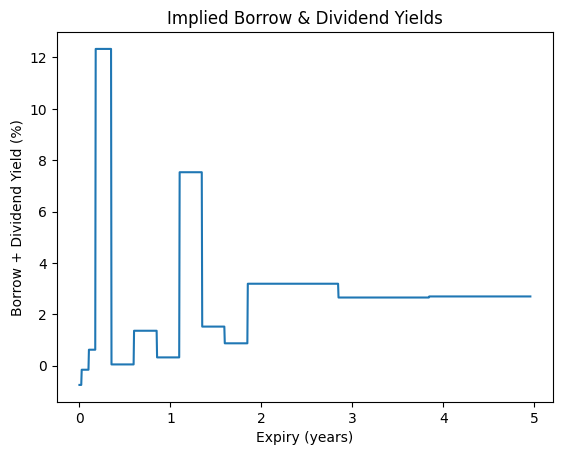

CAC40 2025-02-12 : S0 = 8042.19, 142 quotes on 13 expiries
Heston : v0=0.0197, theta=0.0438, kappa=1.3079, xi=0.4820, rho=-0.6050 | implied vol RMSE = 0.421 vol pts


In [2]:
mkt = cac40_heston()
heston, S0 = mkt.heston, mkt.S0

pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=52, seed=42)
daily_pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42)

## 2. Pricing

`report` gathers the terms of the contract, the price (with its 95% Monte Carlo confidence interval), the fair coupon (the coupon that prices the note at par) and the scenario statistics.

In [3]:
base = Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6)
table, calls = base.report(pricer, heston, name="Base case", by_date=True)
table

Base case
Contract  maturity (years)                              4
          number of observations                       16
          observation frequency (years)              0.25
          coupon (% p.a.)                               6
          coupon type                            snowball
          first autocall barrier (%)                  100
          last autocall barrier (%)                   100
          step-down per observation (%)                 0
          first call date (years)                    0.25
          protection barrier (%)                       60
          protection type                        european
          redemption if knocked-in               standard
          capital guaranteed (%)                        0
          buffer (%)                                    0
          range accrual (%)                          none
          duo barrier (%)                            none
          duo coupon ratio                           none
          look back                                  none
          nominal                                     100
Pricing   price                                   97.7953
          95% confidence (+/-)                   0.109523
          price (% nominal)                       97.7953
          fair coupon (% p.a.)                    10.5382
Scenarios probability to reach maturity            0.1329
          probability of a capital loss           0.05218
          expected loss at maturity (% nominal)   3.05192
          expected life (years)                   1.03247
          expected number of coupons               0.8671
          expected coupon paid (% nominal)        3.00522

Probability of a call at each observation date, and cumulated :

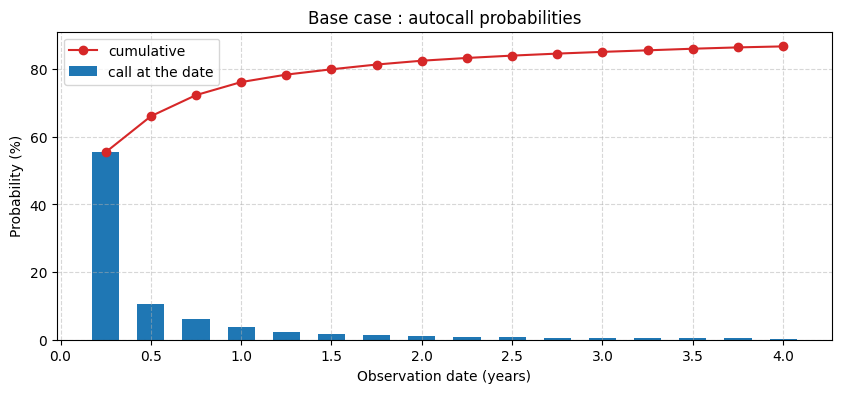

observation date
0.25   55.428
0.5    66.062
0.75   72.306
1      76.162
1.25    78.37
1.5    79.938
1.75   81.348
2      82.476
2.25   83.292
2.5    83.984
2.75   84.578
3       85.09
3.25   85.546
3.5     86.02
3.75   86.412
4       86.71
Name: cumulative, dtype: float64

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(calls.index, 100 * calls["call probability"], width=0.15, label="call at the date")
ax.plot(calls.index, 100 * calls["cumulative"], "o-", color="tab:red", label="cumulative")
ax.set_xlabel("Observation date (years)")
ax.set_ylabel("Probability (%)")
ax.set_title("Base case : autocall probabilities")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.show()
100 * calls["cumulative"]

Some simulated scenarios, grouped by outcome (called early, redeemed at par at maturity, capital loss) :

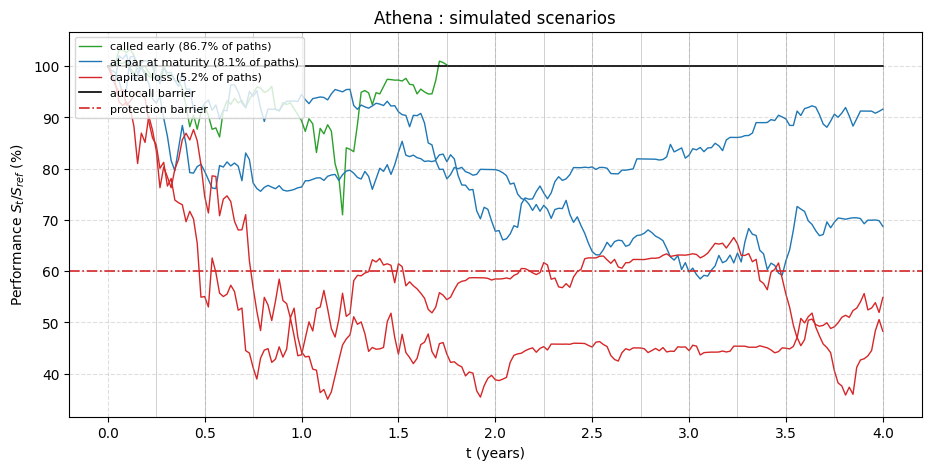

In [5]:
plot_scenarios(pricer, heston, base)

**Reading.** Most of the value comes from the first observation dates : the note is very likely to be called early, so its expected life is short and the coupon actually received is far below $4 \times 6\%$. The investor is short a down-and-in put : the capital loss is rare but large, since the redemption jumps from 100 to 60 at the protection barrier.

## 3. Sensitivities

To compare a variant with the base case, `compare` prices it, keeps its report in `reports` (used in the summary of section 4) and only displays the terms of the contract that differ from the base case.

In [6]:
reports = {"Base case": table}

def compare(name, note, note_pricer=pricer):
    """ Report of note next to the base case, with only the contract terms that differ. """
    reports[name] = note.report(note_pricer, heston, name=name)
    out = pd.concat([table, reports[name]], axis=1)
    contract = out.loc["Contract"].astype(str)
    changed = [("Contract", k) for k in contract.index[contract.nunique(axis=1) > 1]]
    return out.loc[changed + [i for i in out.index if i[0] != "Contract"]]


def sweep(parameter, values, **terms):
    """ Fair coupon and scenario statistics of the base case when one parameter moves. """
    rows = {}
    for x in values:
        note = Athena(4.0, S0, 0.06, **{**dict(frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6), **terms, parameter: x})
        stats = note.statistics(pricer, heston)
        rows[x] = {"fair coupon (% p.a.)": 100 * note.fair_coupon(pricer, heston),
                   "probability of a capital loss (%)": 100 * stats["probability of a capital loss"],
                   "expected loss (% nominal)": stats["expected loss at maturity (% nominal)"],
                   "expected life (years)": stats["expected life (years)"]}
    return pd.DataFrame(rows).T.rename_axis(parameter)


def plot_sweep(df, title):
    fig, axes = plt.subplots(1, len(df.columns), figsize=(4.2 * len(df.columns), 3.4))
    for ax, column in zip(axes, df.columns):
        ax.plot(100 * df.index, df[column], "o-")
        ax.set_title(column, fontsize=10)
        ax.set_xlabel(f"{df.index.name} (%)")
        ax.grid(True, linestyle="--", alpha=0.5)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

### 3.1 Protection barrier

In [7]:
compare("Protection 80%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.8))

Base case Protection 80%
Contract  protection barrier (%)                       60             80
Pricing   price                                   97.7953        96.5991
          95% confidence (+/-)                   0.109523       0.120649
          price (% nominal)                       97.7953        96.5991
          fair coupon (% p.a.)                    10.5382         13.003
Scenarios probability to reach maturity            0.1329         0.1329
          probability of a capital loss           0.05218        0.09568
          expected loss at maturity (% nominal)   3.05192        4.34222
          expected life (years)                   1.03247        1.03247
          expected number of coupons               0.8671         0.8671
          expected coupon paid (% nominal)        3.00522        3.00522

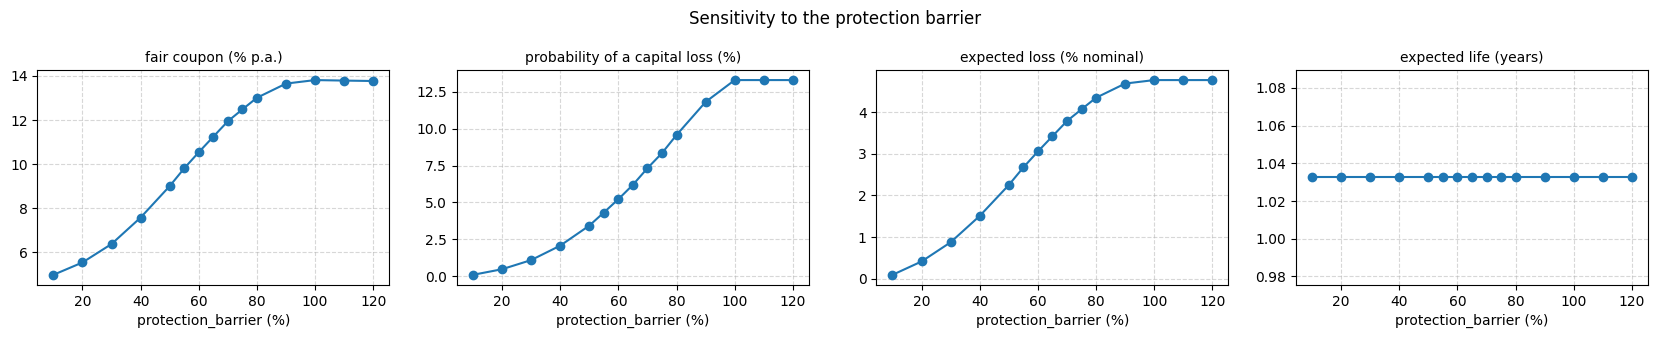

,fair coupon (% p.a.),probability of a capital loss (%),expected loss (% nominal),expected life (years)
protection_barrier,,,,
0.1,4.98744,0.096,0.0897484,1.03247
0.2,5.54687,0.476,0.410783,1.03247
0.3,6.38215,1.094,0.871943,1.03247
0.4,7.57998,2.072,1.50469,1.03247
0.5,9.00468,3.428,2.24682,1.03247
0.55,9.80869,4.316,2.66903,1.03247
0.6,10.5382,5.218,3.05192,1.03247
0.65,11.2411,6.194,3.4177,1.03247
0.7,11.9396,7.318,3.78266,1.03247


In [8]:
protection_sweep = sweep("protection_barrier", [0.1, 0.2, 0.3, 0.4, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9, 1.0, 1.1, 1.2])
plot_sweep(protection_sweep, "Sensitivity to the protection barrier")
protection_sweep

A higher protection barrier means that the investor sells a more valuable down-and-in put : the capital is lost more often, and the fair coupon increases to pay for it. The call probabilities and the expected life do not move, since the protection only matters at maturity.

### 3.2 Autocall barrier

In [9]:
compare("Autocall 110%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.1, protection_barrier=0.6))

Base case Autocall 110%
Contract  first autocall barrier (%)                  100           110
          last autocall barrier (%)                   100           110
Pricing   price                                   97.7953        94.333
          95% confidence (+/-)                   0.109523      0.116345
          price (% nominal)                       97.7953        94.333
          fair coupon (% p.a.)                    10.5382       12.6875
Scenarios probability to reach maturity            0.1329       0.37564
          probability of a capital loss           0.05218        0.1048
          expected loss at maturity (% nominal)   3.05192       6.03887
          expected life (years)                   1.03247       2.39018
          expected number of coupons               0.8671       0.62436
          expected coupon paid (% nominal)        3.00522       5.32575

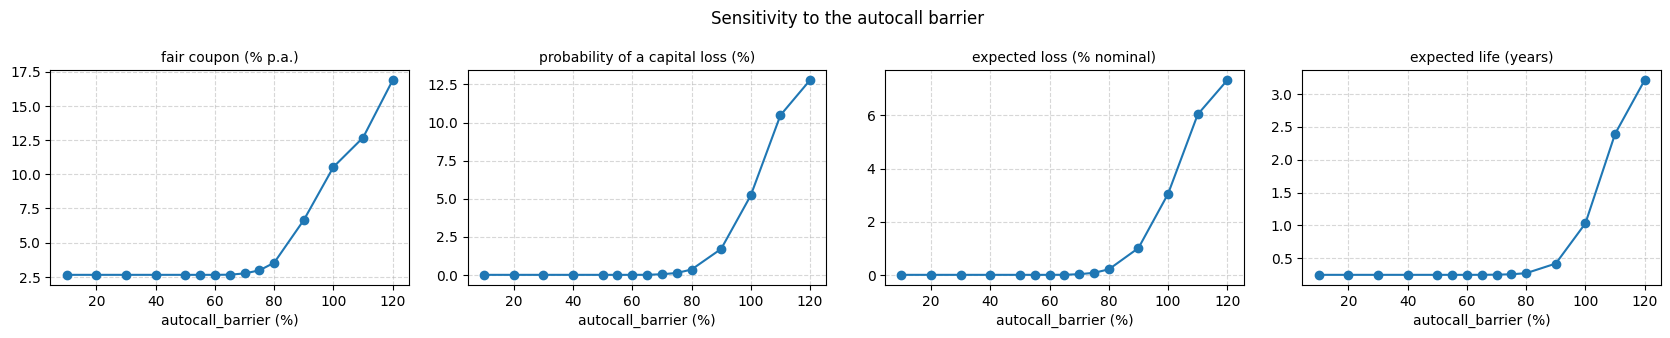

,fair coupon (% p.a.),probability of a capital loss (%),expected loss (% nominal),expected life (years)
autocall_barrier,,,,
0.1,2.64873,0,0,0.25
0.2,2.64873,0,0,0.25
0.3,2.64873,0,0,0.25
0.4,2.64873,0,0,0.25
0.5,2.64873,0,0,0.25
0.55,2.64873,0,0,0.25
0.6,2.64872,0,0,0.25001
0.65,2.66021,0.004,0.00286781,0.25044
0.7,2.75269,0.038,0.0242467,0.252665


In [10]:
autocall_sweep = sweep("autocall_barrier", [0.1, 0.2, 0.3, 0.4, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9, 1.0, 1.1, 1.2])
plot_sweep(autocall_sweep, "Sensitivity to the autocall barrier")
autocall_sweep

A higher autocall barrier makes the call less likely : the note lives longer, more paths reach maturity and are exposed to the put, so the fair coupon increases.

### 3.3 Market parameters

The note is now kept unchanged (coupon 6%, barriers of the base case) and the market moves : volatility, dividends, rates, issuer spread, maturity and skew. `market_sweep` prices the base case under each scenario.

In [11]:
class SpreadPricer(MonteCarloPricer):
    """ Discounts the cash flows of the note at r(t) + spread (issuer credit / funding), the drift staying at r(t) - q(t).
    The control variate (a put discounted at r) is switched off, since its exact price would not match. """
    def __init__(self, spread, **kwargs):
        super().__init__(control_variate=False, **kwargs)
        self.spread = spread

    def discount_factors(self, model, maturity, M):
        grid = np.linspace(0.0, maturity, M + 1)
        return super().discount_factors(model, maturity, M) * np.exp(-self.spread * grid)


def market_sweep(name, scenarios, note=None):
    """ Price at 6%, fair coupon and scenario statistics of note (base case by default) under each scenario
    {x: (model, pricer)}. """
    rows = {}
    for x, (model, p) in scenarios.items():
        n = base if note is None else note(x)
        stats = n.statistics(p, model)
        rows[x] = {"price at 6%": p.price(model, n).price,
                   "fair coupon (% p.a.)": 100 * n.fair_coupon(p, model),
                   "call at 1st date (%)": 100 * list(stats["call probability by date"].values())[0],
                   "probability of a capital loss (%)": 100 * stats["probability of a capital loss"],
                   "expected life (years)": stats["expected life (years)"]}
    return pd.DataFrame(rows).T.rename_axis(name)


def plot_market_sweep(df, title, columns=("price at 6%", "fair coupon (% p.a.)", "probability of a capital loss (%)", "expected life (years)")):
    fig, axes = plt.subplots(1, len(columns), figsize=(4.2 * len(columns), 3.4))
    for ax, column in zip(axes, columns):
        ax.plot(df.index, df[column], "o-")
        ax.set_title(column, fontsize=10)
        ax.set_xlabel(df.index.name)
        ax.grid(True, linestyle="--", alpha=0.5)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

#### Volatility

$\sqrt{v_0}$ and $\sqrt{\theta}$ are shifted together, from $-3$ to $+3$ vol points.

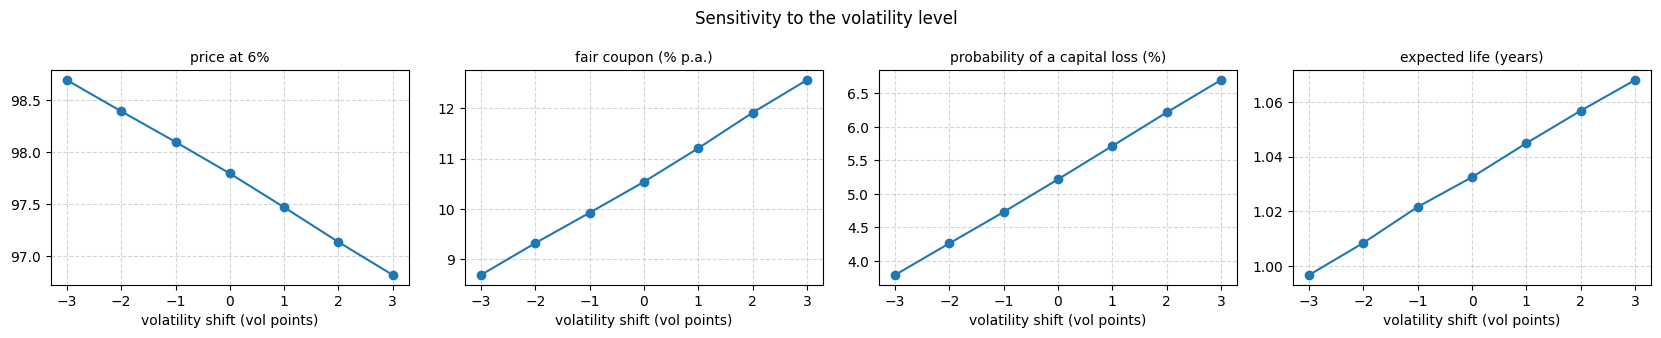

,price at 6%,fair coupon (% p.a.),call at 1st date (%),probability of a capital loss (%),expected life (years)
volatility shift (vol points),,,,,
-3,98.6958,8.68589,56.818,3.79,0.99673
-2,98.3946,9.31993,56.326,4.262,1.00846
-1,98.0996,9.92348,55.864,4.73,1.02161
0,97.7953,10.5382,55.428,5.218,1.03247
1,97.469,11.2064,55.076,5.716,1.04489
2,97.1344,11.9143,54.63,6.216,1.05673
3,96.8166,12.5631,54.17,6.7,1.06795


In [12]:
vol_sweep = market_sweep("volatility shift (vol points)", {d: (bump_vol(heston, d / 100), pricer) for d in [-3, -2, -1, 0, 1, 2, 3]})
plot_market_sweep(vol_sweep, "Sensitivity to the volatility level")
vol_sweep

#### Dividends

Parallel shift of the borrow + dividend yield $q(t)$, from $-1\%$ to $+1\%$ (rates unchanged : every forward moves by $e^{-\Delta q \, T}$).

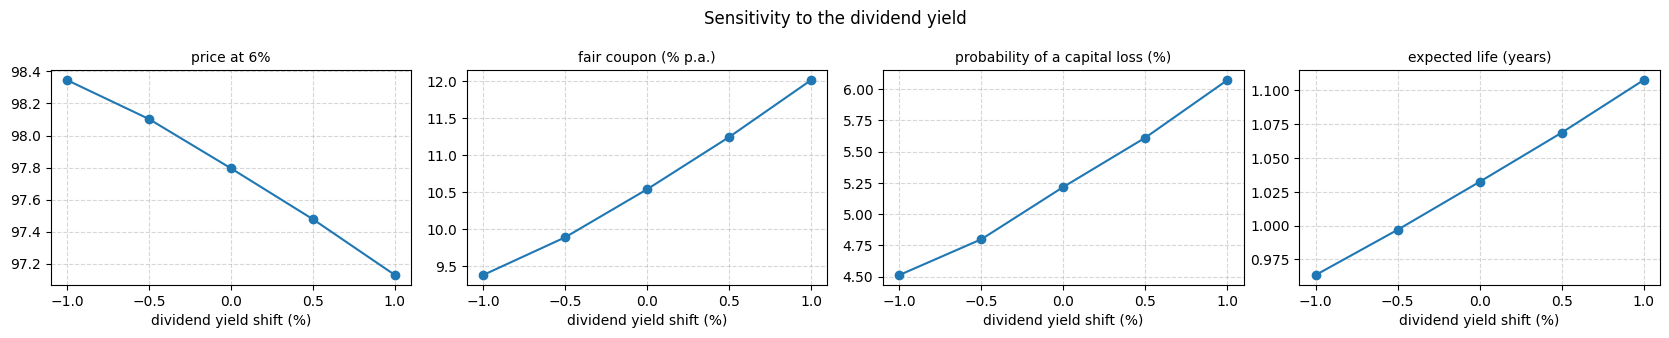

,price at 6%,fair coupon (% p.a.),call at 1st date (%),probability of a capital loss (%),expected life (years)
dividend yield shift (%),,,,,
-1,98.3462,9.37614,56.952,4.514,0.96352
-0.5,98.1031,9.88691,56.198,4.8,0.99699
0,97.7953,10.5382,55.428,5.218,1.03247
0.5,97.4775,11.2456,54.67,5.612,1.06878
1,97.1293,12.0177,53.88,6.072,1.10771


In [13]:
dividend_sweep = market_sweep("dividend yield shift (%)", {d: (bump_carry(heston, d / 100), pricer) for d in [-1, -0.5, 0, 0.5, 1]})
plot_market_sweep(dividend_sweep, "Sensitivity to the dividend yield")
dividend_sweep

#### Risk-free rate

Parallel shift of the zero-coupon curve, from $-1\%$ to $+1\%$. The dividend yield is kept, so the forwards move by $e^{\Delta r \, T}$ and the discount factors by $e^{-\Delta r \, T}$.

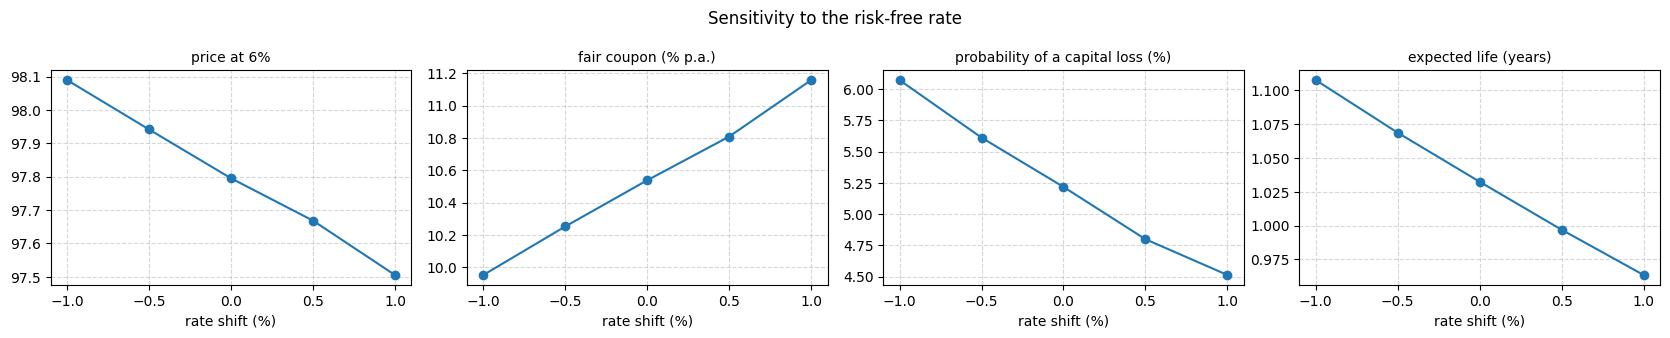

,price at 6%,fair coupon (% p.a.),call at 1st date (%),probability of a capital loss (%),expected life (years)
rate shift (%),,,,,
-1,98.0896,9.95141,53.88,6.072,1.10771
-0.5,97.9416,10.2522,54.67,5.612,1.06878
0,97.7953,10.5382,55.428,5.218,1.03247
0.5,97.6684,10.8091,56.198,4.8,0.99699
1,97.5055,11.159,56.952,4.514,0.96352


In [14]:
rate_sweep = market_sweep("rate shift (%)", {d: (bump_rate(heston, d / 100), pricer) for d in [-1, -0.5, 0, 0.5, 1]})
plot_market_sweep(rate_sweep, "Sensitivity to the risk-free rate")
rate_sweep

#### Issuer spread

The cash flows are discounted at $r(t) + s$, $s$ being the funding / credit spread of the issuer, while the drift of the index is unchanged. The control variate is switched off for this sweep, so the price at $s = 0$ differs slightly from the base case (Monte Carlo noise).

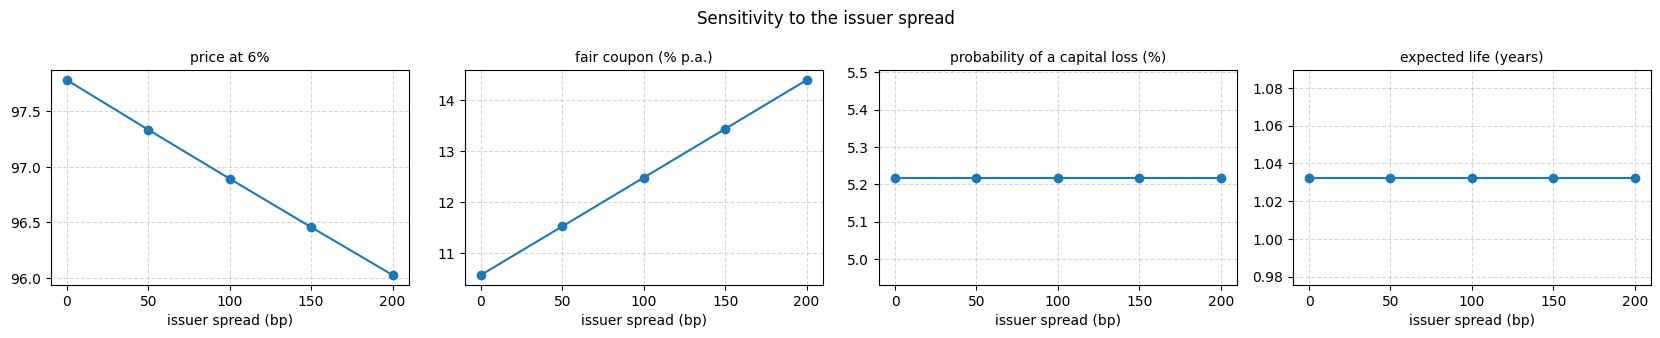

,price at 6%,fair coupon (% p.a.),call at 1st date (%),probability of a capital loss (%),expected life (years)
issuer spread (bp),,,,,
0,97.7807,10.5695,55.428,5.218,1.03247
50,97.3344,11.5248,55.428,5.218,1.03247
100,96.8936,12.4809,55.428,5.218,1.03247
150,96.4582,13.4378,55.428,5.218,1.03247
200,96.028,14.3956,55.428,5.218,1.03247


In [15]:
spread_sweep = market_sweep("issuer spread (bp)", {s: (heston, SpreadPricer(s / 1e4, n_paths=50_000, steps_per_year=52, seed=42)) for s in [0, 50, 100, 150, 200]})
plot_market_sweep(spread_sweep, "Sensitivity to the issuer spread")
spread_sweep

#### Maturity

Same note with a maturity from 1 to 5 years (5 years is slightly beyond the last listed expiry, 4.86 years).

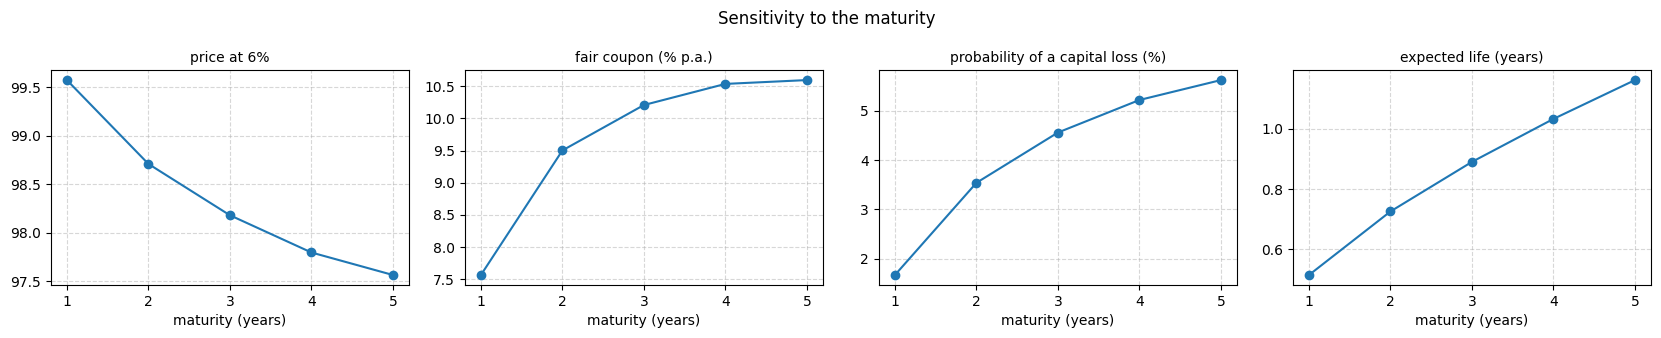

,price at 6%,fair coupon (% p.a.),call at 1st date (%),probability of a capital loss (%),expected life (years)
maturity (years),,,,,
1,99.5721,7.56265,55.428,1.668,0.51551
2,98.7082,9.50237,55.428,3.538,0.725965
3,98.1792,10.2093,55.428,4.558,0.89014
4,97.7953,10.5382,55.428,5.218,1.03247
5,97.5634,10.5978,55.428,5.622,1.16111


In [16]:
maturity_sweep = market_sweep("maturity (years)", {T: (heston, pricer) for T in [1, 2, 3, 4, 5]},
                              note=lambda T: Athena(float(T), S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6))
plot_market_sweep(maturity_sweep, "Sensitivity to the maturity")
maturity_sweep

#### Skew (spot-volatility correlation)

In the Heston model, the skew of the implied volatility surface is mainly driven by the spot-variance correlation $\rho$ (calibrated at $-0.605$). We move $\rho$ alone, the variance level being unchanged : a more negative $\rho$ steepens the skew, i.e. makes the low strikes (the protection barrier) more expensive. The price of the 4-year European put struck at 60% (in % of $S_0$) measures how expensive the low strikes become.

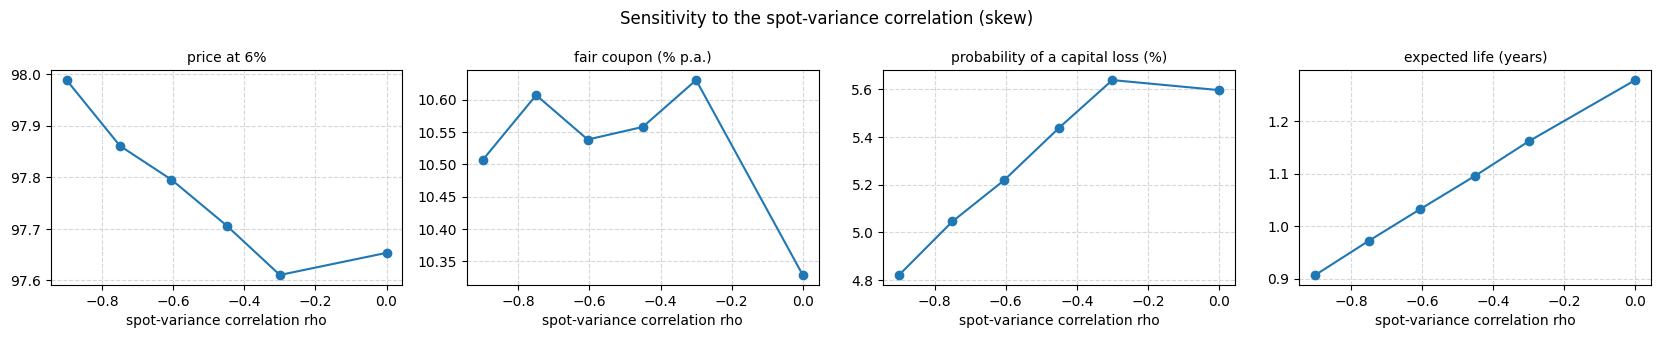

,price at 6%,fair coupon (% p.a.),call at 1st date (%),probability of a capital loss (%),expected life (years),4y put 60% price
spot-variance correlation rho,,,,,,
-0.9,97.9882,10.5069,59.968,4.822,0.906875,2.38609
-0.75,97.8608,10.6068,57.68,5.046,0.97185,2.28177
-0.605,97.7953,10.5382,55.428,5.218,1.03247,2.16812
-0.45,97.7064,10.5577,53.162,5.438,1.09624,2.03193
-0.3,97.6106,10.6301,51.008,5.638,1.16178,1.88467
0,97.6534,10.3291,46.892,5.596,1.27872,1.53951


In [17]:
import copy

def with_rho(rho):
    """ Copy of the calibrated Heston model with another spot-variance correlation. """
    model = copy.copy(heston)
    model.rho = rho
    return model

skew_sweep = market_sweep("spot-variance correlation rho", {rho: (with_rho(rho), pricer) for rho in [-0.9, -0.75, -0.605, -0.45, -0.3, 0.0]})
skew_sweep["4y put 60% price"] = [float(with_rho(r).price_vanillas([0.6 * S0], 4.0, False)[0]) / S0 * 100 for r in skew_sweep.index]
plot_market_sweep(skew_sweep, "Sensitivity to the spot-variance correlation (skew)")
skew_sweep

### 3.4 Hedging

The issuer is short the note : it is long the down-and-in put sold by the investor and short the autocall feature. Its main risks are the delta (hedged with futures on the index), the vega (hedged with listed puts) and the dividends (hedged with dividend futures). We compute the Greeks of the base case as functions of the spot, the initial fixing staying at $S_0$.

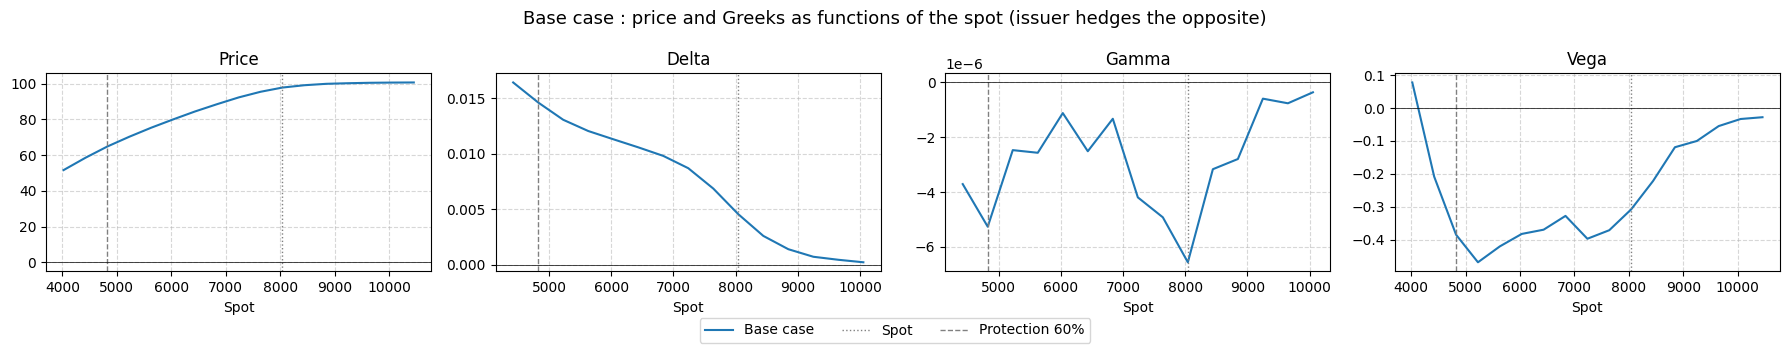

,price,delta,gamma,vega,rho,theta
spot,,,,,,
4021.09,51.6535,NaN,NaN,0.0774931,0.832394,0.00461437
4423.2,58.5601,0.0164295,-3.71212e-06,-0.208646,0.610975,0.00623991
4825.31,64.8664,0.0146237,-5.26923e-06,-0.385087,0.270644,0.00544977
5227.42,70.3208,0.0130674,-2.47164e-06,-0.468891,-0.0154198,0.00350151
5629.53,75.3755,0.0120541,-2.56814e-06,-0.420596,-0.14009,0.00220791
6031.64,80.0149,0.011313,-1.11828e-06,-0.382757,-0.421953,0.00298067
6433.75,84.4736,0.0105831,-2.51173e-06,-0.369861,-0.27089,0.000214114
6835.86,88.5261,0.00981151,-1.32614e-06,-0.327939,-0.221498,0.00619964
7237.97,92.3642,0.00870114,-4.19656e-06,-0.397402,-0.45962,0.0102638


In [18]:
profile_pricer = MonteCarloPricer(n_paths=30_000, steps_per_year=52, seed=42)
spots = S0 * np.linspace(0.5, 1.3, 17)
base_profiles = Greeks(profile_pricer).profiles(heston, [base], spots, greeks=("delta", "gamma", "vega", "rho", "theta"), labels=["Base case"])
plot_greek_profiles(base_profiles, greeks=("price", "delta", "gamma", "vega"), vlines={"Spot": S0, "Protection 60%": 0.6 * S0},
                    title="Base case : price and Greeks as functions of the spot (issuer hedges the opposite)")
base_profiles["Base case"]

In [19]:
# Hedge of the issuer at inception, for a nominal of 100 : it is short the note, so it holds the opposite of its Greeks.
g = Greeks(pricer).compute(heston, base, ("delta", "vega", "rho", "dividend"))["value"]
K = 0.6 * S0
put = lambda m: float(m.price_vanillas([K], 4.0, False)[0])
put_vega = (put(bump_vol(heston, 0.01)) - put(bump_vol(heston, -0.01))) / 2        # per vol point, per unit of index
hedge = pd.Series({
    "note delta (per index point)": g["delta"],
    "index exposure of the note (% nominal)": 100 * g["delta"] * S0 / 100,
    "issuer : index units to buy": g["delta"],
    "note vega (per vol point)": g["vega"],
    "4y 60% put vega (per vol point, per unit)": put_vega,
    "issuer : 4y 60% puts to sell (units)": -g["vega"] / put_vega,
    "note rho (per +1%)": g["rho"],
    "note dividend (per +1%)": g["dividend"],
}, name="Base case")
hedge.to_frame()

,Base case
note delta (per index point),0.00469712
index exposure of the note (% nominal),37.7751
issuer : index units to buy,0.00469712
note vega (per vol point),-0.315332
"4y 60% put vega (per vol point, per unit)",19.3163
issuer : 4y 60% puts to sell (units),0.0163247
note rho (per +1%),-0.209613
note dividend (per +1%),-0.688754


**Reading.** The note behaves like a fraction of a position in the index : its delta is the exposure that the issuer must buy back with futures. When the spot falls towards the protection barrier, the delta of the note increases (the short put gets closer to the money) and the issuer must buy more index in a falling market. Close to maturity, the jump of the redemption at the protection barrier makes the delta and the gamma very large around the barrier (pin risk), which is the main hedging difficulty. The issuer is long volatility and long dividends : it hedges the vega by selling listed puts around the protection barrier, and the dividends with dividend futures.

## 4. Features of Athena products

We now look at the features that can be added to the Athena product and at their impact on the price. Every variant is compared with the base case, all the other terms being equal.

### 4.1 Observation frequency

The autocall barrier is now observed every day (1008 observation dates) instead of every quarter. The daily grid is needed, since the weekly one is too coarse for these dates.

In [20]:
compare("Daily observation", Athena(4.0, S0, 0.06, frequency=1/252, autocall_barrier=1.0, protection_barrier=0.6), daily_pricer)

Base case Daily observation
Contract  number of observations                       16              1008
          observation frequency (years)              0.25        0.00396825
          first call date (years)                    0.25        0.00396825
Pricing   price                                   97.7953            99.651
          95% confidence (+/-)                   0.109523          0.049185
          price (% nominal)                       97.7953            99.651
          fair coupon (% p.a.)                    10.5382           11.7368
Scenarios probability to reach maturity            0.1329           0.01796
          probability of a capital loss           0.05218           0.00778
          expected loss at maturity (% nominal)   3.05192          0.455526
          expected life (years)                   1.03247          0.134455
          expected number of coupons               0.8671           0.98204
          expected coupon paid (% nominal)        3.00522          0.375689

In [21]:
# observation frequency : annual, semi-annual and monthly (quarterly is the base case)
for name, f in [("Annual observation", 1.0), ("Semi-annual observation", 0.5), ("Monthly observation", 1 / 12)]:
    reports[name] = Athena(4.0, S0, 0.06, frequency=f, autocall_barrier=1.0, protection_barrier=0.6).report(pricer, heston, name=name)
frequency_names = ["Annual observation", "Semi-annual observation", "Base case", "Monthly observation", "Daily observation"]
pd.concat([reports[n] for n in frequency_names], axis=1).drop(index="Contract", level=0)

Annual observation  \
Pricing   price                                            96.6062   
          95% confidence (+/-)                            0.118702   
          price (% nominal)                                96.6062   
          fair coupon (% p.a.)                             9.41201   
Scenarios probability to reach maturity                    0.25704   
          probability of a capital loss                     0.0906   
          expected loss at maturity (% nominal)            5.27305   
          expected life (years)                            2.06456   
          expected number of coupons                       0.74296   
          expected coupon paid (% nominal)                  6.2184   

                                                Semi-annual observation  \
Pricing   price                                                 97.2204   
          95% confidence (+/-)                                 0.116821   
          price (% nominal)                                     97.2204   
          fair coupon (% p.a.)                                  9.92822   
Scenarios probability to reach maturity                          0.1861   
          probability of a capital loss                         0.06972   
          expected loss at maturity (% nominal)                 4.07502   
          expected life (years)                                 1.47667   
          expected number of coupons                             0.8139   
          expected coupon paid (% nominal)                      4.39362   

                                                Base case Monthly observation  \
Pricing   price                                   97.7953             98.6215   
          95% confidence (+/-)                   0.109523           0.0918033   
          price (% nominal)                       97.7953             98.6215   
          fair coupon (% p.a.)                    10.5382             11.1144   
Scenarios probability to reach maturity            0.1329             0.07766   
          probability of a capital loss           0.05218             0.03128   
          expected loss at maturity (% nominal)   3.05192             1.83039   
          expected life (years)                   1.03247            0.588053   
          expected number of coupons               0.8671             0.92234   
          expected coupon paid (% nominal)        3.00522             1.66448   

                                                Daily observation  
Pricing   price                                            99.651  
          95% confidence (+/-)                           0.049185  
          price (% nominal)                                99.651  
          fair coupon (% p.a.)                            11.7368  
Scenarios probability to reach maturity                   0.01796  
          probability of a capital loss                   0.00778  
          expected loss at maturity (% nominal)          0.455526  
          expected life (years)                          0.134455  
          expected number of coupons                      0.98204  
          expected coupon paid (% nominal)               0.375689

### 4.2 Step-down barrier

The autocall barrier decreases by 1% at each observation, from 100% to 85% at maturity. The call becomes easier over time.

In [22]:
compare("Step-down 1%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, step_down=0.01))

Base case Step-down 1%
Contract  last autocall barrier (%)                   100           85
          step-down per observation (%)                 0            1
Pricing   price                                   97.7953      98.8083
          95% confidence (+/-)                   0.109523      0.10446
          price (% nominal)                       97.7953      98.8083
          fair coupon (% p.a.)                    10.5382      8.23821
Scenarios probability to reach maturity            0.1329      0.08118
          probability of a capital loss           0.05218       0.0444
          expected loss at maturity (% nominal)   3.05192      2.61864
          expected life (years)                   1.03247       0.8738
          expected number of coupons               0.8671      0.91882
          expected coupon paid (% nominal)        3.00522      3.29448

### 4.3 Airbag

The put is struck at the protection barrier : below 60%, the redemption is $100 \, S_T / (0.6 \, S_{ref})$. There is no more loss jump at the barrier.

In [23]:
compare("Airbag", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, put_strike=0.6))

Base case    Airbag
Contract  redemption if knocked-in               standard    airbag
Pricing   price                                   97.7953   99.1098
          95% confidence (+/-)                   0.109523 0.0746021
          price (% nominal)                       97.7953   99.1098
          fair coupon (% p.a.)                    10.5382   7.83238
Scenarios probability to reach maturity            0.1329    0.1329
          probability of a capital loss           0.05218   0.05218
          expected loss at maturity (% nominal)   3.05192   1.60787
          expected life (years)                   1.03247   1.03247
          expected number of coupons               0.8671    0.8671
          expected coupon paid (% nominal)        3.00522   3.00522

### 4.4 Buffer

The first 10% of decline is absorbed by the issuer : below 90%, the investor loses one for one, $100 \, (S_T / S_{ref} + 10\%)$, without loss jump.

In [24]:
compare("Buffer 10%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.9, buffer=0.1))

Base case  Buffer 10%
Contract  protection barrier (%)                       60          90
          redemption if knocked-in               standard  buffer 10%
          buffer (%)                                    0          10
Pricing   price                                   97.7953     97.3663
          95% confidence (+/-)                   0.109523     0.10254
          price (% nominal)                       97.7953     97.3663
          fair coupon (% p.a.)                    10.5382     11.4234
Scenarios probability to reach maturity            0.1329      0.1329
          probability of a capital loss           0.05218     0.11808
          expected loss at maturity (% nominal)   3.05192     3.50149
          expected life (years)                   1.03247     1.03247
          expected number of coupons               0.8671      0.8671
          expected coupon paid (% nominal)        3.00522     3.00522

### 4.5 Guaranteed capital

The redemption at maturity is floored : `floor=1.0` guarantees 100% of the capital, `floor=0.9` guarantees 90%.

In [25]:
compare("Guaranteed 100%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, floor=1.0))

Base case Guaranteed 100%
Contract  capital guaranteed (%)                        0             100
Pricing   price                                   97.7953         100.568
          95% confidence (+/-)                   0.109523       0.0362875
          price (% nominal)                       97.7953         100.568
          fair coupon (% p.a.)                    10.5382         4.82995
Scenarios probability to reach maturity            0.1329          0.1329
          probability of a capital loss           0.05218               0
          expected loss at maturity (% nominal)   3.05192               0
          expected life (years)                   1.03247         1.03247
          expected number of coupons               0.8671          0.8671
          expected coupon paid (% nominal)        3.00522         3.00522

In [26]:
compare("Guaranteed 90%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, floor=0.9))

Base case Guaranteed 90%
Contract  capital guaranteed (%)                        0             90
Pricing   price                                   97.7953        100.094
          95% confidence (+/-)                   0.109523      0.0458459
          price (% nominal)                       97.7953        100.094
          fair coupon (% p.a.)                    10.5382        5.80665
Scenarios probability to reach maturity            0.1329         0.1329
          probability of a capital loss           0.05218        0.05218
          expected loss at maturity (% nominal)   3.05192         0.5218
          expected life (years)                   1.03247        1.03247
          expected number of coupons               0.8671         0.8671
          expected coupon paid (% nominal)        3.00522        3.00522

### 4.6 Coupon range accrual

The coupon only accrues on the (weekly) simulation dates where $80\% \leq S_t / S_{ref} \leq 120\%$.

In [27]:
compare("Range accrual 80-120%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, accrual_range=(0.8, 1.2)))

Base case  \
Contract  range accrual (%)                          none   
Pricing   price                                   97.7953   
          95% confidence (+/-)                   0.109523   
          price (% nominal)                       97.7953   
          fair coupon (% p.a.)                    10.5382   
Scenarios probability to reach maturity            0.1329   
          probability of a capital loss           0.05218   
          expected loss at maturity (% nominal)   3.05192   
          expected life (years)                   1.03247   
          expected number of coupons               0.8671   
          expected coupon paid (% nominal)        3.00522   

                                                Range accrual 80-120%  
Contract  range accrual (%)                                 [80, 120]  
Pricing   price                                               97.6764  
          95% confidence (+/-)                               0.108702  
          price (% nominal)                                   97.6764  
          fair coupon (% p.a.)                                10.9862  
Scenarios probability to reach maturity                        0.1329  
          probability of a capital loss                       0.05218  
          expected loss at maturity (% nominal)               3.05192  
          expected life (years)                               1.03247  
          expected number of coupons                           0.8671  
          expected coupon paid (% nominal)                     2.8789

### 4.7 Duo mechanism

Two call levels : the note is called with the full coupon above 100%, and with half of the coupon between 90% and 100%.

In [28]:
compare("Duo 90% / 50%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, duo_barrier=0.9, duo_coupon_ratio=0.5))

Base case Duo 90% / 50%
Contract  duo barrier (%)                            none            90
          duo coupon ratio                           none           0.5
Pricing   price                                   97.7953       99.3724
          95% confidence (+/-)                   0.109523     0.0693994
          price (% nominal)                       97.7953       99.3724
          fair coupon (% p.a.)                    10.5382       8.85779
Scenarios probability to reach maturity            0.1329       0.03132
          probability of a capital loss           0.05218       0.01704
          expected loss at maturity (% nominal)   3.05192       1.00956
          expected life (years)                   1.03247       0.42151
          expected number of coupons               0.8671       0.96868
          expected coupon paid (% nominal)        3.00522        1.3335

### 4.8 Look back

The reference level $S_{ref}$ is the minimum of the index over the first month instead of the initial fixing (`lookback_type='average'` gives an Asian fixing).

In [29]:
compare("Look back min 1m", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, lookback=1/12, lookback_type='min'))

Base case     Look back min 1m
Contract  look back                                  none  min over 0.0833333y
Pricing   price                                   97.7953              98.7453
          95% confidence (+/-)                   0.109523            0.0953223
          price (% nominal)                       97.7953              98.7453
          fair coupon (% p.a.)                    10.5382              9.07992
Scenarios probability to reach maturity            0.1329               0.0903
          probability of a capital loss           0.05218              0.03572
          expected loss at maturity (% nominal)   3.05192              2.08984
          expected life (years)                   1.03247             0.778975
          expected number of coupons               0.8671               0.9097
          expected coupon paid (% nominal)        3.00522              2.50665

### 4.9 Protection type

The protection is now American : the capital is at risk as soon as the index touches 60% at any time before maturity, continuously (Brownian bridge on the weekly grid) or on daily closes (daily grid).

In [30]:
compare("American protection", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, protection_type="american"))

Base case American protection
Contract  protection type                        european            american
Pricing   price                                   97.7953             96.8297
          95% confidence (+/-)                   0.109523            0.122128
          price (% nominal)                       97.7953             96.8297
          fair coupon (% p.a.)                    10.5382             12.5258
Scenarios probability to reach maturity            0.1329              0.1329
          probability of a capital loss           0.05218           0.0921762
          expected loss at maturity (% nominal)   3.05192             4.10912
          expected life (years)                   1.03247             1.03247
          expected number of coupons               0.8671              0.8671
          expected coupon paid (% nominal)        3.00522             3.00522

In [31]:
compare("American protection (daily)", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, protection_type="american_discrete"), daily_pricer)

Base case  \
Contract  protection type                        european   
Pricing   price                                   97.7953   
          95% confidence (+/-)                   0.109523   
          price (% nominal)                       97.7953   
          fair coupon (% p.a.)                    10.5382   
Scenarios probability to reach maturity            0.1329   
          probability of a capital loss           0.05218   
          expected loss at maturity (% nominal)   3.05192   
          expected life (years)                   1.03247   
          expected number of coupons               0.8671   
          expected coupon paid (% nominal)        3.00522   

                                                American protection (daily)  
Contract  protection type                                 american_discrete  
Pricing   price                                                     96.9221  
          95% confidence (+/-)                                     0.122272  
          price (% nominal)                                         96.9221  
          fair coupon (% p.a.)                                      12.3143  
Scenarios probability to reach maturity                             0.13226  
          probability of a capital loss                              0.0898  
          expected loss at maturity (% nominal)                        4.06  
          expected life (years)                                     1.03146  
          expected number of coupons                                0.86774  
          expected coupon paid (% nominal)                          3.01452

### 4.10 Non-call period

The note cannot be called during the first year : the first callable date is $t = 1$.

In [32]:
compare("Non-call 1 year", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, first_call_date=1.0))

Base case Non-call 1 year
Contract  first call date (years)                    0.25               1
Pricing   price                                   97.7953          97.152
          95% confidence (+/-)                   0.109523        0.117382
          price (% nominal)                       97.7953          97.152
          fair coupon (% p.a.)                    10.5382         8.94384
Scenarios probability to reach maturity            0.1329         0.22064
          probability of a capital loss           0.05218         0.08416
          expected loss at maturity (% nominal)   3.05192         4.91549
          expected life (years)                   1.03247         1.88512
          expected number of coupons               0.8671         0.77936
          expected coupon paid (% nominal)        3.00522         6.01533

### 4.11 Coupon type

The coupon is fixed instead of snowball : a call at $t_k$ pays $c \, (t_k - t_{k-1})$, whatever the call date.

In [33]:
compare("Fixed coupon", Athena(4.0, S0, 0.06, coupon_type="fixed", frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6))

Base case Fixed coupon
Contract  coupon type                            snowball        fixed
Pricing   price                                   97.7953      96.1635
          95% confidence (+/-)                   0.109523      0.10135
          price (% nominal)                       97.7953      96.1635
          fair coupon (% p.a.)                    10.5382      23.9411
Scenarios probability to reach maturity            0.1329       0.1329
          probability of a capital loss           0.05218      0.05218
          expected loss at maturity (% nominal)   3.05192      3.05192
          expected life (years)                   1.03247      1.03247
          expected number of coupons               0.8671       0.8671
          expected coupon paid (% nominal)        3.00522      1.30065

### 4.12 Summary

All the variants priced above, with a coupon of 6% p.a. :

In [34]:
summary = pd.concat(reports.values(), axis=1).drop(index="Contract", level=0).droplevel(0).T.astype(float)
summary = summary.drop(columns=["price (% nominal)"])
summary.sort_values("fair coupon (% p.a.)")

,price,95% confidence (+/-),fair coupon (% p.a.),probability to reach maturity,probability of a capital loss,expected loss at maturity (% nominal),expected life (years),expected number of coupons,expected coupon paid (% nominal)
Guaranteed 100%,100.568,0.0362875,4.82995,0.1329,0,0,1.03247,0.8671,3.00522
Guaranteed 90%,100.094,0.0458459,5.80665,0.1329,0.05218,0.5218,1.03247,0.8671,3.00522
Airbag,99.1098,0.0746021,7.83238,0.1329,0.05218,1.60787,1.03247,0.8671,3.00522
Step-down 1%,98.8083,0.10446,8.23821,0.08118,0.0444,2.61864,0.8738,0.91882,3.29448
Duo 90% / 50%,99.3724,0.0693994,8.85779,0.03132,0.01704,1.00956,0.42151,0.96868,1.3335
Non-call 1 year,97.152,0.117382,8.94384,0.22064,0.08416,4.91549,1.88512,0.77936,6.01533
Look back min 1m,98.7453,0.0953223,9.07992,0.0903,0.03572,2.08984,0.778975,0.9097,2.50665
Annual observation,96.6062,0.118702,9.41201,0.25704,0.0906,5.27305,2.06456,0.74296,6.2184
Semi-annual observation,97.2204,0.116821,9.92822,0.1861,0.06972,4.07502,1.47667,0.8139,4.39362
Base case,97.7953,0.109523,10.5382,0.1329,0.05218,3.05192,1.03247,0.8671,3.00522


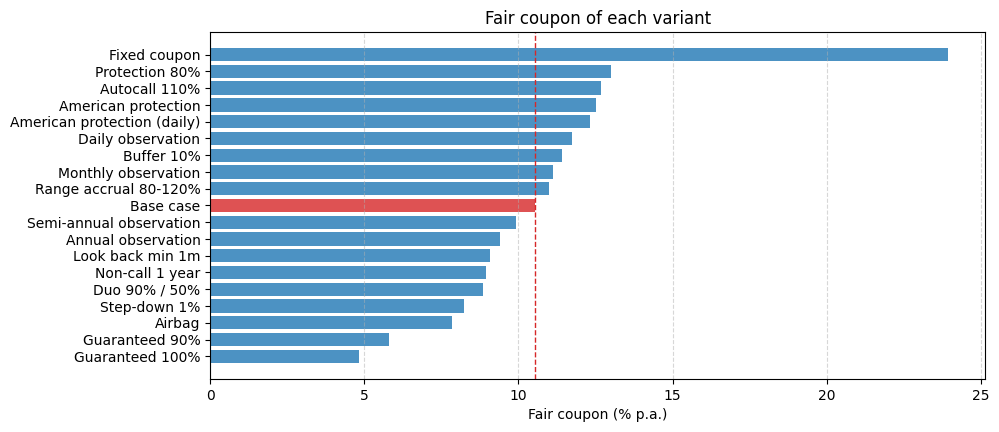

In [35]:
fair = summary["fair coupon (% p.a.)"].sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["tab:red" if name == "Base case" else "tab:blue" for name in fair.index]
ax.barh(fair.index, fair.values, color=colors, alpha=0.8)
ax.axvline(fair["Base case"], color="tab:red", linestyle="--", linewidth=1)
ax.set_xlabel("Fair coupon (% p.a.)")
ax.set_title("Fair coupon of each variant")
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
plt.show()

Redemption at maturity of the variants that change the capital protection, if the note was never called :

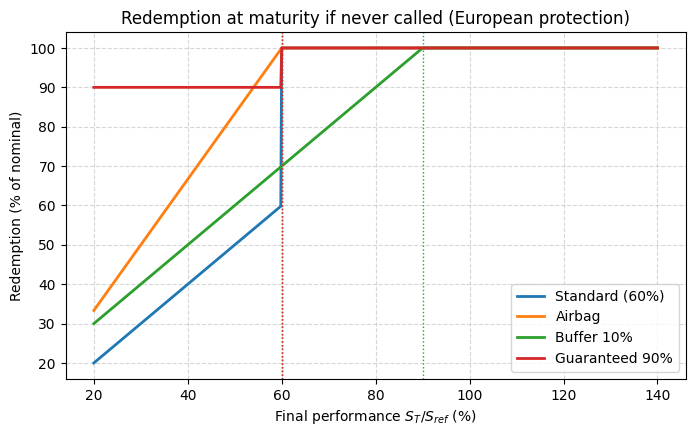

<Axes: title={'center': 'Redemption at maturity if never called (European protection)'}, xlabel='Final performance $S_T / S_{ref}$ (%)', ylabel='Redemption (% of nominal)'>

In [36]:
plot_redemption_profiles({
    "Standard (60%)": base,
    "Airbag": Athena(4.0, S0, 0.06, frequency=0.25, protection_barrier=0.6, put_strike=0.6),
    "Buffer 10%": Athena(4.0, S0, 0.06, frequency=0.25, protection_barrier=0.9, buffer=0.1),
    "Guaranteed 90%": Athena(4.0, S0, 0.06, frequency=0.25, protection_barrier=0.6, floor=0.9),
})

Call probabilities of the variants that change the autocall mechanism :

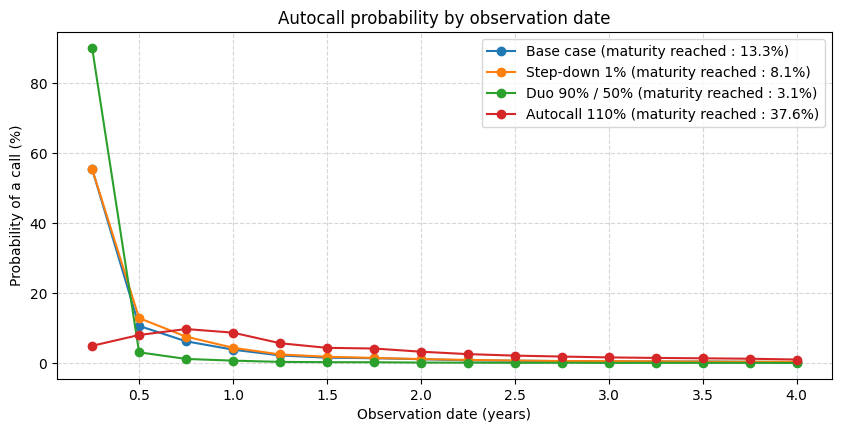

In [37]:
plot_call_probabilities(pricer, heston, {
    "Base case": base,
    "Step-down 1%": Athena(4.0, S0, 0.06, frequency=0.25, step_down=0.01),
    "Duo 90% / 50%": Athena(4.0, S0, 0.06, frequency=0.25, duo_barrier=0.9, duo_coupon_ratio=0.5),
    "Autocall 110%": Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.1),
})

**Reading.** The features that make the call easier (step-down, duo, look back) or that reduce the loss at maturity (airbag, guaranteed capital) are more valuable for the investor, so their fair coupon is lower than in the base case. The features that make the loss more likely (higher protection barrier or autocall barrier, buffer, which starts losing below 90%) or the coupon smaller (range accrual) are paid by a higher fair coupon.

The daily observation is the exception : the call is almost certain within a few weeks, so the loss nearly disappears, but the snowball coupon $c \, t_k$ is then paid on a very short life. A much higher coupon rate is needed to price the note at par.

## 5. Greeks

Greeks of the base case and of the variants that change the capital protection, by finite differences on the same paths (delta per unit of spot, vega per vol point, rho per +1% of rates, theta per day).

In [38]:
greek_notes = {
    "Base case": base,
    "American protection": Athena(4.0, S0, 0.06, frequency=0.25, protection_barrier=0.6, protection_type="american"),
    "Step-down 1%": Athena(4.0, S0, 0.06, frequency=0.25, step_down=0.01),
    "Airbag": Athena(4.0, S0, 0.06, frequency=0.25, protection_barrier=0.6, put_strike=0.6),
    "Guaranteed 90%": Athena(4.0, S0, 0.06, frequency=0.25, protection_barrier=0.6, floor=0.9),
}
greeks = Greeks(pricer).table(heston, list(greek_notes.values()), labels=list(greek_notes), with_stderr=True,
                              greeks=("delta", "gamma", "vega", "vanna", "volga", "rho", "dividend", "theta"))
greeks["delta 1%"] = greeks["delta"] * S0 / 100                       # value change of a 1% move of the index
greeks[[c for c in greeks.columns if not c.endswith("stderr")]]

,price,delta,gamma,vega,vanna,volga,rho,dividend,theta,delta 1%
Base case,97.7953,0.00469712,-8.58043e-06,-0.315332,0.000244823,-0.0220015,-0.209613,-0.688754,0.00476735,0.377751
American protection,96.8297,0.00640083,-1.0044e-05,-0.375247,0.00020412,-0.00501076,-0.05839,-0.801177,0.00370592,0.514767
Step-down 1%,98.8083,0.00224738,-7.30446e-06,-0.298906,0.000285702,-0.0111481,-0.421188,-0.354067,0.00396802,0.180739
Airbag,99.1098,0.00260267,-6.21034e-06,-0.205024,0.000169848,-0.0228362,-0.485512,-0.465206,0.00244142,0.209312
Guaranteed 90%,100.094,0.00113651,-3.73467e-06,-0.0663329,6.90938e-05,-0.0111808,-0.683101,-0.307136,0.00190582,0.0914


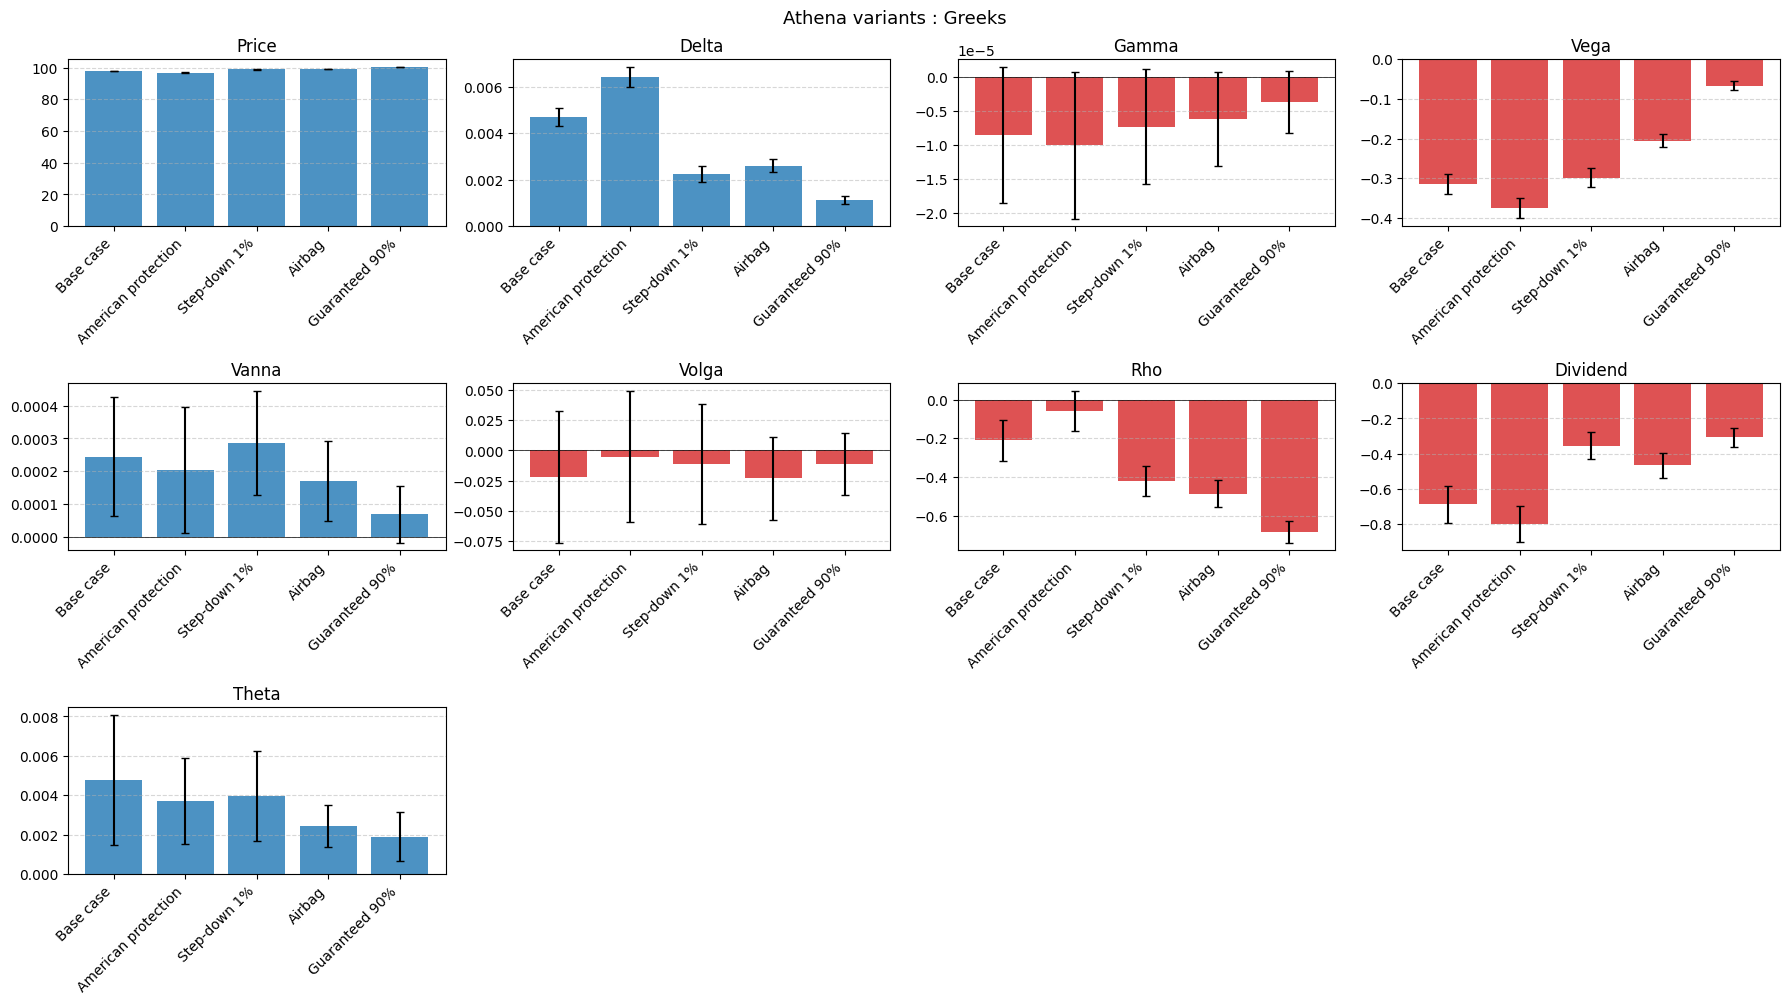

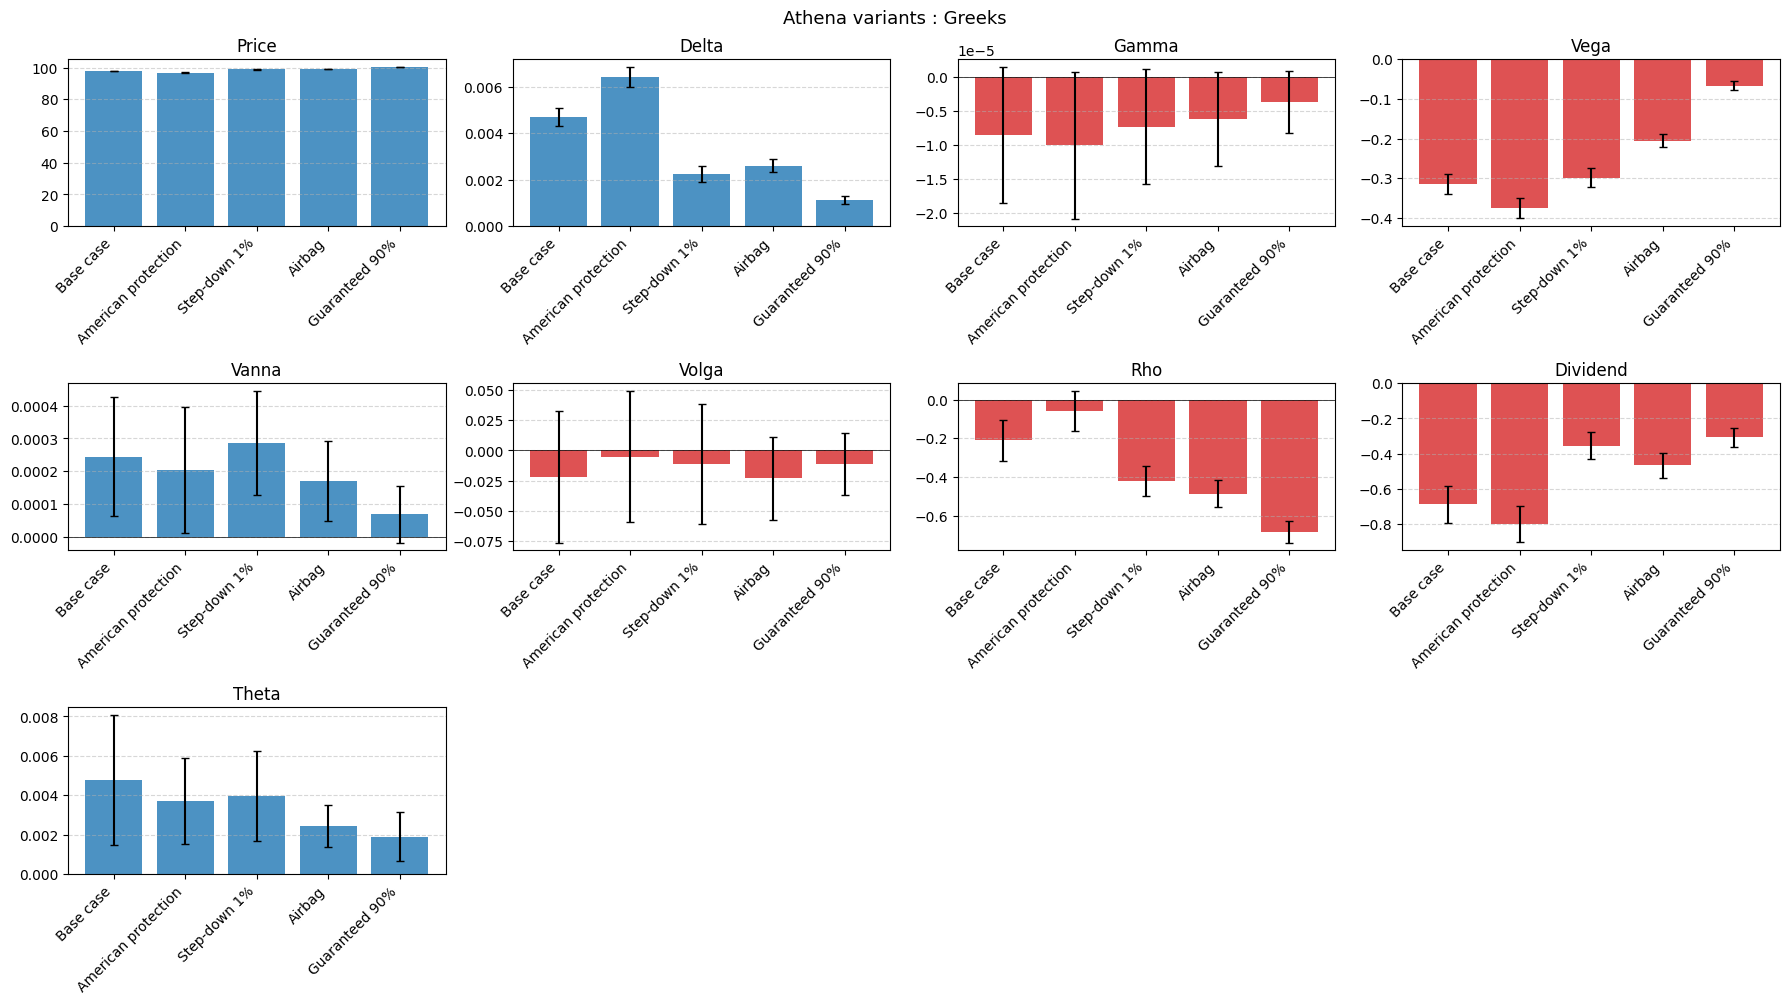

In [39]:
plot_greeks_bars(greeks, greeks=("price", "delta", "gamma", "vega", "vanna", "volga", "rho", "dividend", "theta"), title="Athena variants : Greeks")

In [40]:
# standard errors of the base case, and sensitivities to the Heston parameters (per unit of parameter)
display(greeks.loc["Base case", [c for c in greeks.columns if c.endswith("stderr")]].to_frame())
Greeks(pricer).parameter_sensitivities(heston, base)

,Base case
price stderr,0.0558793
delta stderr,0.000199322
gamma stderr,5.12412e-06
vega stderr,0.0130115
vanna stderr,9.23976e-05
volga stderr,0.0277341
rho stderr,0.0537962
dividend stderr,0.0539435
theta stderr,0.00168078


,value,stderr
d/dv0,-61.7407,14.1902
d/dtheta,-18.6117,8.99246
d/dkappa,0.106525,0.258578
d/dxi,2.91151,1.19179
d/drho,-1.05612,0.801677


**Reading.** The investor is long the underlying (positive delta, through the call and the short put) and short volatility (negative vega) : a higher volatility makes the knock-in more likely. Flooring the capital removes most of the short put : the delta and the vega shrink, and the note behaves more like a zero-coupon bond, with a more negative rho.